# Expressing domain knowledge about media contributions

Search and TikTok budgets often rise together. Sales may be predictable while their separate contributions remain uncertain. Here we express partial business knowledge directly on historical contribution shares, without translating it into saturation or adstock parameters.

We compare the same correctly specified MMM with its existing parameter priors, with a paid-media group belief, and with both group and TikTok beliefs. We then deliberately supply a wrong belief. This example assumes useful domain knowledge; it is **not experimental calibration**. Familiarity with the [MMM introduction](mmm_example.ipynb) and [prior predictive checks](../general/prior_predictive.ipynb) is helpful.

## Setup and known truth

A shared planning process drives both spends, with modest independent variation. It has **no direct effect on sales**. Sales depend on the two transformed spends, a constant baseline, and independent Normal noise. Accounting for both channels therefore gives a correctly specified conditional outcome model. Correlated responses create weak identification in this finite dataset, rather than omitted-variable bias.

We choose the seed, DGP parameters, and illustrative business beliefs below before looking at posterior results. The beliefs are broad business judgments, not estimates calculated from the answer key. Revenue and spend are in USD; the fixed scaling constants only express model parameters in manageable units.

In [1]:
import io
import warnings

import arviz as az
import graphviz
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import seaborn as sns
import xarray as xr
from IPython.display import display
from matplotlib.dates import ConciseDateFormatter, MonthLocator
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from pymc.model.transform.optimization import freeze_dims_and_data
from pymc_extras.prior import Prior
from pytensor.xtensor import as_xtensor
from scipy.stats import gaussian_kde

from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation
from pymc_marketing.mmm.scaling import FixedScaling, Scaling

warnings.filterwarnings("ignore", message="IProgress not found.*")
warnings.filterwarnings("ignore", message="Cannot cache compiled function.*")

%config InlineBackend.figure_format = "retina"
plt.rcParams.update(
    {
        "figure.constrained_layout.use": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
FIG_WIDTH, FIG_HEIGHT = 10, 3.6
SEARCH, TIKTOK, MEDIA = "#0072B2", "#D55E00", "#009E73"
ENTITY_COLORS = {"search": SEARCH, "tiktok": TIKTOK, "paid_media": MEDIA}
VARIANTS = ["Base", "Group belief", "Both beliefs"]
STYLES = {
    "Base": (0.4, ":"),
    "Group belief": (0.7, "--"),
    "Both beliefs": (1.0, "-"),
    "Wrong belief": (1.0, "-."),
}
SEED = 42
rng = np.random.default_rng(SEED)

# Elicited judgments, set before fitting and independently of the planted truth.
paid_media_belief = Prior("Normal").constrain(lower=0.20, upper=0.40, mass=0.90)
tiktok_belief = Prior("Normal", mu=0.0, sigma=0.025)
wrong_tiktok_belief = Prior("Normal", mu=0.18, sigma=0.01)


def format_dates(ax):
    locator = MonthLocator(bymonth=[1, 7])
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(ConciseDateFormatter(locator))

The group component puts 90% of its own density between 20% and 40%. The smooth TikTok component puts only about 2.3% of its own mass above 5%; it also has density at negative values. These statements describe the supplied components, **not the effective prior on model contributions**. The model's existing nonnegative channel effects still determine which shares are possible.

In [2]:
N = 80
planning = np.zeros(N)
for t in range(1, N):
    planning[t] = 0.8 * planning[t - 1] + rng.normal(0, 9)
spend = 55 + planning[:, None] + rng.normal(0, 1.8, size=(N, 2))
assert np.all(spend > 0)  # noqa: S101
X = pd.DataFrame(spend, columns=["search", "tiktok"])
X.insert(0, "date", pd.date_range("2024-01-01", periods=N, freq="W-MON"))

adstock = GeometricAdstock(l_max=4, normalize=True)
saturation = LogisticSaturation()
true_alpha = as_xtensor(np.array([0.3, 0.3]), dims=("channel",))
true_lam = as_xtensor(np.array([2.0, 2.0]), dims=("channel",))
true_beta = as_xtensor(np.array([0.70, 0.06]), dims=("channel",))
adstocked = adstock.function(
    x=as_xtensor(spend / 100, dims=("date", "channel")), alpha=true_alpha, dim="date"
)
true_contribution = (
    (100 * saturation.function(x=adstocked, lam=true_lam, beta=true_beta))
    .transpose("date", "channel")
    .values.eval()
)
true_mean = 70 + true_contribution.sum(axis=1)
y = pd.Series(true_mean + rng.normal(0, 2.5, N))
true_shares = dict(
    zip(["search", "tiktok"], true_contribution.sum(axis=0) / y.sum(), strict=False)
)
true_shares["paid_media"] = sum(true_shares.values())
# Compare unit-amplitude responses, which matter for attribution ambiguity.
responses = (
    saturation.function(x=adstocked, lam=true_lam, beta=1.0)
    .transpose("date", "channel")
    .values.eval()
)
display(
    pd.Series(
        {
            "Raw spend correlation": np.corrcoef(spend.T)[0, 1],
            "Transformed response correlation": np.corrcoef(responses.T)[0, 1],
            **{f"True {k} share": v for k, v in true_shares.items()},
        }
    ).to_frame("Value")
)

,Value
Raw spend correlation,0.973663
Transformed response correlation,0.982280
True search share,0.324892
True tiktok share,0.027804
True paid_media share,0.352696


Both raw spends and unit-amplitude transformed responses move together. The small TikTok truth lies below the illustrative 5% upper-tail threshold. The true shares above divide original-unit contributions by this particular dataset's observed sales total, matching the API definition.

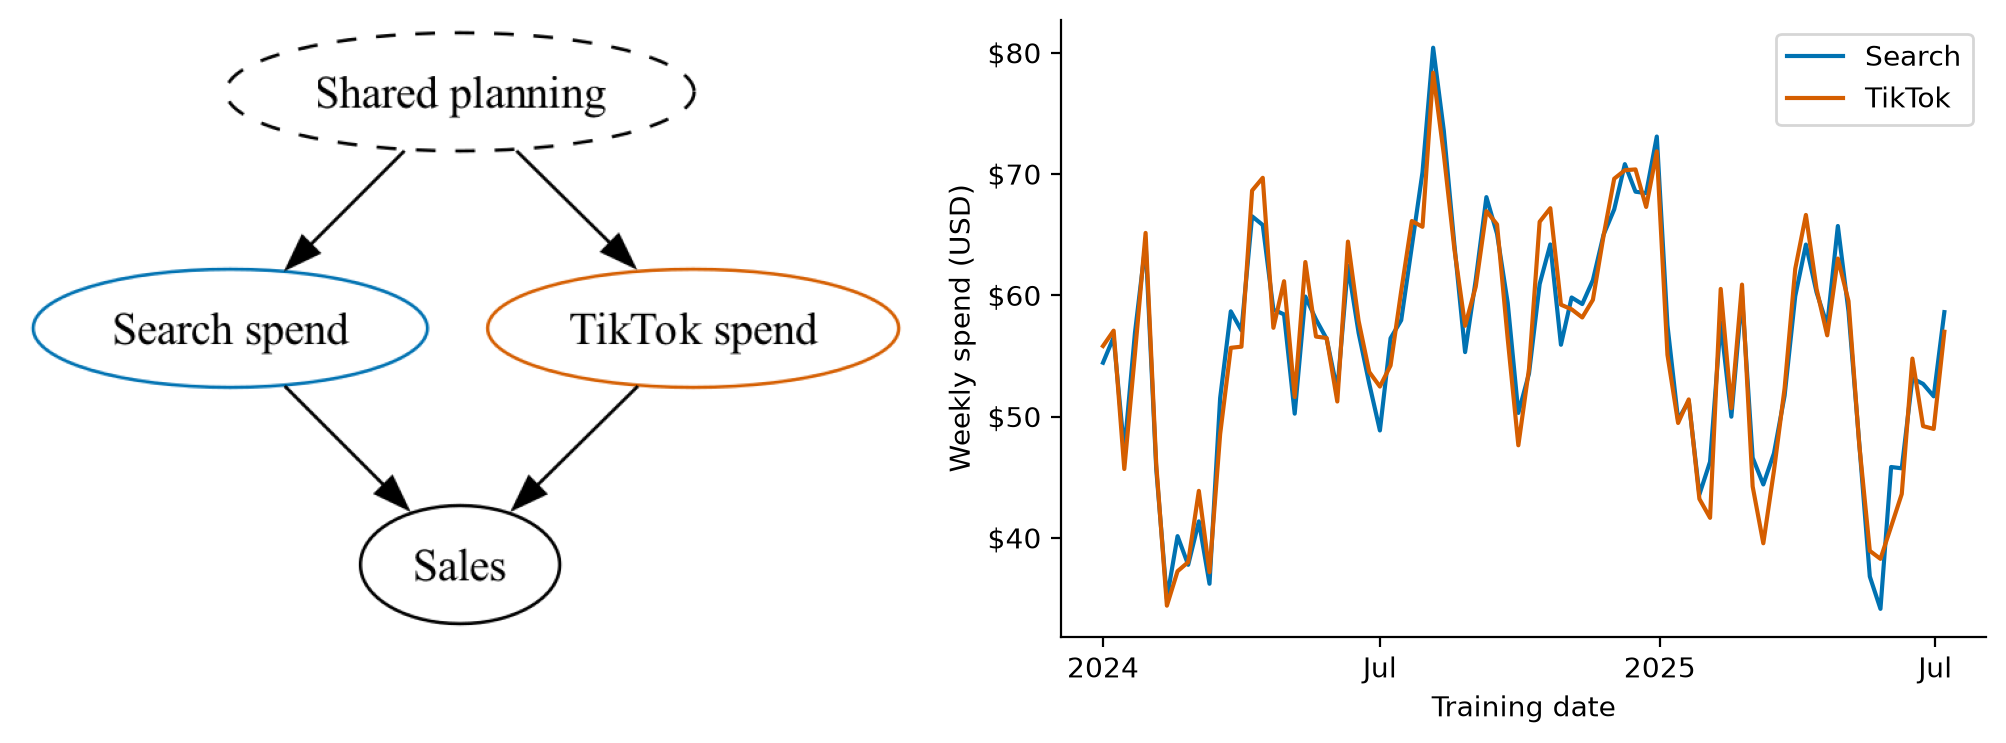

In [3]:
dag = graphviz.Digraph()
dag.attr(rankdir="TB", bgcolor="transparent", dpi="180")
dag.node("p", "Shared planning", style="dashed")
dag.node("s", "Search spend", color=SEARCH)
dag.node("t", "TikTok spend", color=TIKTOK)
dag.node("y", "Sales")
dag.edges([("p", "s"), ("p", "t"), ("s", "y"), ("t", "y")])
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, FIG_HEIGHT))
axes[0].imshow(plt.imread(io.BytesIO(dag.pipe(format="png"))))
axes[0].axis("off")
for j, (channel, color) in enumerate([("search", SEARCH), ("tiktok", TIKTOK)]):
    axes[1].plot(
        X.date,
        spend[:, j],
        label=channel.title().replace("Tiktok", "TikTok"),
        color=color,
    )
axes[1].set(ylabel="Weekly spend (USD)", xlabel="Training date")
axes[1].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].legend()
format_dates(axes[1])
plt.show()

**Caption:** Planning creates a fork into the two measured spends; each spend affects sales through adstock and saturation. The dashed planning node is unobserved, but has no additional sales pathway. Weekly spend paths have modest channel-specific variation.

## Sales fit leaves attribution uncertain

The model below uses the same transformations as the DGP, while learning their parameters. All variants retain these parameter priors and the same Normal likelihood. The baseline and observation noise are correctly specified; there is no seasonality or hidden sales driver.

Four chains with 1,000 retained draws each support interval comparisons; 1,500 tuning iterations and a 0.95 target acceptance rate help explore the allocation tradeoff. We report convergence diagnostics after sampling rather than assuming that a good sales fit is sufficient.

In [4]:
def build_mmm():
    mmm = MMM(
        date_column="date",
        channel_columns=["search", "tiktok"],
        adstock=GeometricAdstock(l_max=4, normalize=True),
        saturation=LogisticSaturation(),
        scaling=Scaling(
            target=FixedScaling(dims=(), value=100.0),
            channel=FixedScaling(dims=(), value=100.0),
        ),
        model_config={
            "intercept": Prior("Normal", mu=0.7, sigma=0.4),
            "adstock_alpha": Prior("Beta", alpha=6, beta=14, dims="channel"),
            "saturation_lam": Prior("Gamma", mu=2, sigma=0.6, dims="channel"),
            "saturation_beta": Prior("HalfNormal", sigma=1, dims="channel"),
            "likelihood": Prior("Normal", sigma=Prior("HalfNormal", sigma=0.06)),
        },
    )
    mmm.build_model(X, y)
    mmm.add_original_scale_contribution_variable(["channel_contribution"])
    return mmm


SAMPLING = dict(
    draws=1000,
    tune=1500,
    chains=4,
    cores=4,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=SEED,
    progressbar=False,
)
models = {"Base": build_mmm()}
models["Base"].fit(X, y, **SAMPLING)

The baseline model has been sampled. Next compare its training predictions with the known mean and its joint historical channel shares with the known allocation. The diagonal tradeoff, rather than an inaccurate posterior mean, is the relevant symptom of attribution uncertainty.

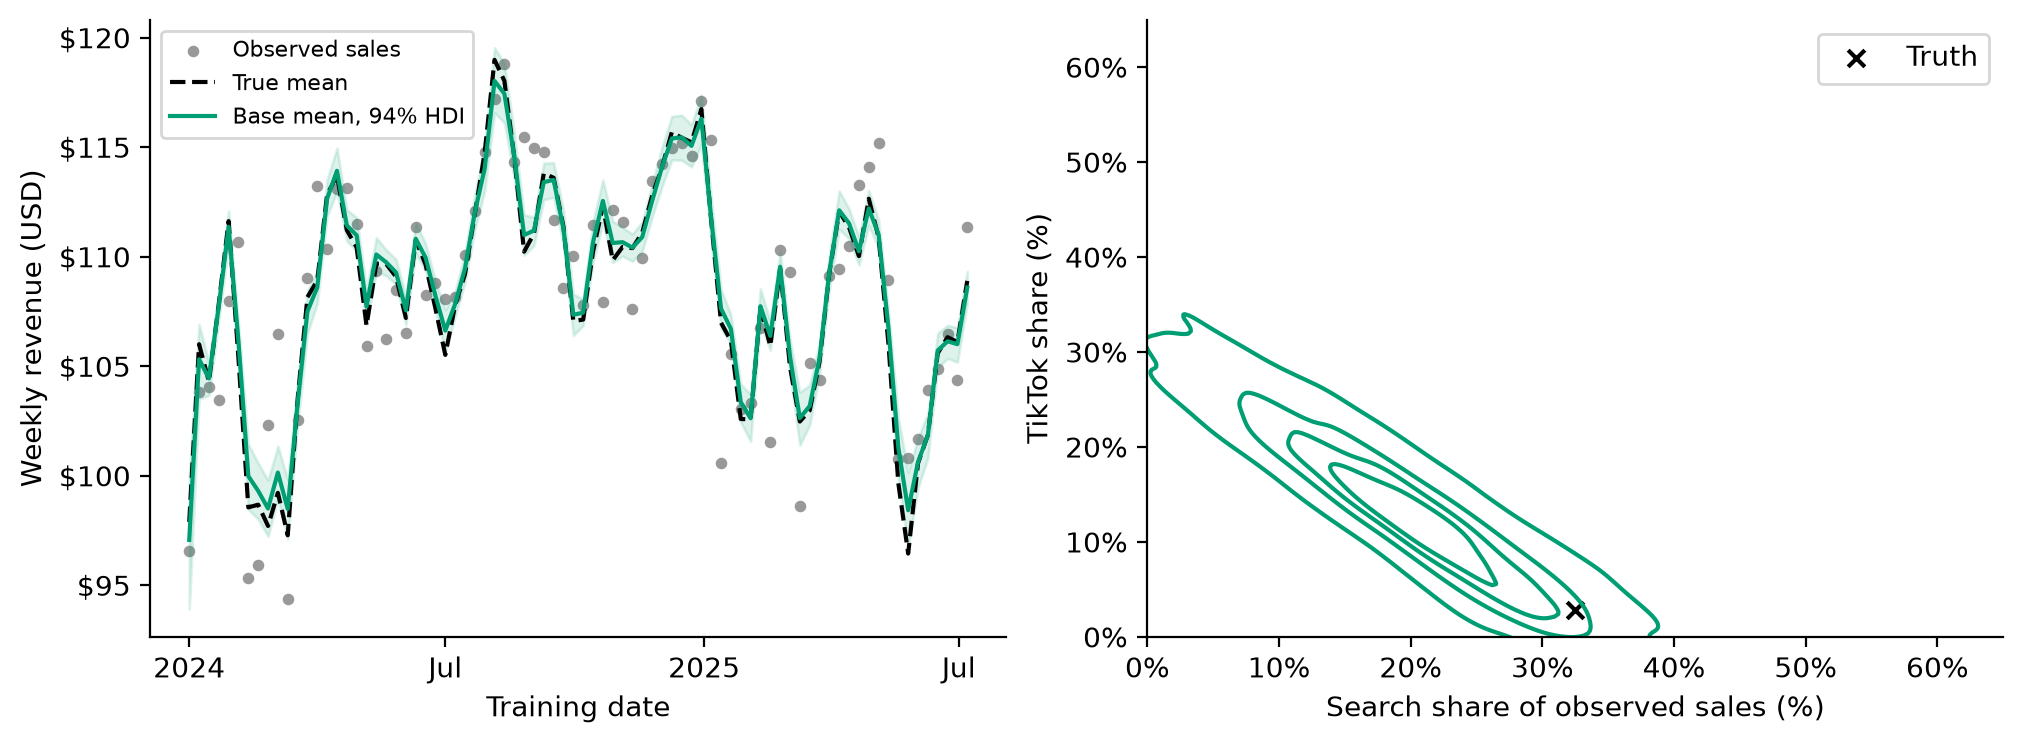

In [5]:
def shares(idata, group="posterior"):
    channel = idata[group]["channel_contribution_original_scale"].sum("date") / y.sum()
    return xr.Dataset(
        {
            "search": channel.sel(channel="search", drop=True),
            "tiktok": channel.sel(channel="tiktok", drop=True),
            "paid_media": channel.sum("channel"),
        }
    )


def interval(draws):
    # ArviZ 1.x uses prob and named sample dimensions.
    return np.asarray(az.hdi(draws, prob=0.94, dim=["chain", "draw"]))


def band(ax, x, draws, color, label, alpha=1.0, linestyle="-"):
    mean = draws.mean(("chain", "draw")).values
    bounds = interval(draws)
    ax.plot(x, mean, color=color, alpha=alpha, linestyle=linestyle, label=label)
    ax.fill_between(x, bounds[..., 0], bounds[..., 1], color=color, alpha=0.13 * alpha)


base = models["Base"].idata
base_shares = shares(base)
base_mean = (
    base.posterior.intercept_contribution * 100
    + base.posterior.channel_contribution_original_scale.sum("channel")
)
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, FIG_HEIGHT))
axes[0].scatter(X.date, y, color="0.6", s=10, label="Observed sales")
axes[0].plot(X.date, true_mean, "k--", label="True mean")
band(axes[0], X.date, base_mean, MEDIA, "Base mean, 94% HDI")
axes[0].set(ylabel="Weekly revenue (USD)", xlabel="Training date")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].legend(fontsize=8)
sns.kdeplot(
    x=base_shares.search.values.ravel(),
    y=base_shares.tiktok.values.ravel(),
    ax=axes[1],
    color=MEDIA,
    levels=5,
)
axes[1].scatter(
    true_shares["search"], true_shares["tiktok"], c="black", marker="x", label="Truth"
)
axes[1].set(
    xlabel="Search share of observed sales (%)",
    ylabel="TikTok share (%)",
    xlim=(0, 0.65),
    ylim=(0, 0.65),
)
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend()
format_dates(axes[0])
plt.show()

**Caption:** Baseline posterior mean revenue and 94% HDI of the conditional mean, alongside the known mean and observed sales. Joint posterior contours expose the channel allocation tradeoff; the cross marks the true historical allocation. The revenue band describes uncertainty in the mean, not observation noise.

A plausible sales curve does not pick out a unique channel decomposition. The model can exchange contribution between these similar response paths. We will compare interval widths and allocation changes directly, rather than requiring the baseline mean to miss the truth.

## Express partial business knowledge

For selected channels $G$, the API evaluates one scalar per parameter draw:

$$C_G(\theta)=\sum_{(t,d)\in O}\sum_{c\in G}\text{contribution}_{t,d,c}(\theta),\qquad
s_G(\theta)=C_G(\theta)/\sum_{(t,d)\in O} y_{t,d}.$$

$O$ contains the training cells with finite original outcomes; additional panel dimensions $d$ are pooled. Contributions and outcomes use original units. Missing outcomes are excluded from both aggregates (the MMM's existing zero-filled sales likelihood is unchanged). Shares require a finite positive observed-outcome sum. A share is relative to **observed training sales**, not total media, so it can exceed 100% and is never clipped or renormalized.

Each named component contributes exactly one log density:

$$p_{\mathrm{effective}}(\theta)\propto p_{\mathrm{existing}}(\theta)\,q_{\mathrm{group}}(s_G(\theta))\,q_{\mathrm{TikTok}}(s_{\mathrm{TikTok}}(\theta)).$$

**This adds factors to the joint prior; it does not replace a marginal prior.** A component's 90% interval does not become a guaranteed 90% interval for the effective contribution prior or posterior. Existing transformation priors stay in place. Groups may overlap or be nested, and omitted channels need no new specification, although their induced priors can change.

This first version supports additive identity-link MMMs without MuEffects, using the existing direct channel contributions. Components must be scalar, centered, untransformed `Prior` objects with fixed finite scalar parameters and smooth support over the real line. Multiplicative links and interaction/mediated attribution are unsupported. In particular, bounded Beta, Uniform, and truncated components—including literal hard caps—are rejected. A Uniform factor would give constant weight inside its bound and zero outside, **not** a uniform effective share. Hard boundaries require additional sampling care; this API does not silently soften them.

In [6]:
group_mmm = build_mmm()
group_mmm.add_contribution_prior(
    name="paid_media_share",
    channels=["search", "tiktok"],
    scale="share",
    prior=paid_media_belief,
)

both_mmm = build_mmm()
both_mmm.add_contribution_prior(
    name="paid_media_share",
    channels=["search", "tiktok"],
    scale="share",
    prior=paid_media_belief,
)
both_mmm.add_contribution_prior(
    name="tiktok_share",
    channels=["tiktok"],
    scale="share",
    prior=tiktok_belief,
)
models.update({"Group belief": group_mmm, "Both beliefs": both_mmm})

`scale="total"` expresses the same belief in absolute original outcome units. Names must be unique: `paid_media_share` is an inspectable aggregate Deterministic and `paid_media_share_prior` is its Potential. Duplicate names raise an error. The training path, scales, coordinates, and original observed-cell mask are frozen, persisted on save/load, and restored on same-data rebuilds. Use a new MMM for a different training dataset. These historical beliefs do not bound future outcomes or alternative budgets.

[`Prior.constrain()`](https://www.pymc.io/projects/extras/en/stable/generated/pymc_extras.prior.Prior.constrain.html) uses PreliZ for elicitation. See [PreliZ's documentation](https://preliz.readthedocs.io/en/latest/) for deeper workflows.

### Inspect the effective prior

PyMC forward prior-predictive sampling ignores Potentials. The MMM emits an explicit warning when contribution factors are present: those forward draws are **base induced priors**, not effective priors.

Instead, freeze model data and use `pm.do` to replace the observed sales RV with an inert constant in a copied graph. This removes its likelihood, without introducing a simulated sales denominator. The assertions verify that no sales observations remain and that all contribution factors survive. MCMC now samples only the existing parameter priors multiplied by those factors; this is an outcome-scaled prior specification, not a posterior fitted to sales. Run this before changing any model inputs.

In [7]:
def sample_effective_prior(mmm):
    frozen = freeze_dims_and_data(mmm.model)
    fixed_sales = frozen[mmm.output_var].type.constant_type(
        type=frozen[mmm.output_var].type, data=np.zeros(N)
    )
    prior_model = pm.do(
        frozen, {mmm.output_var: fixed_sales}, make_interventions_shared=False
    )
    assert not prior_model.observed_RVs  # noqa: S101
    assert len(prior_model.potentials) == len(mmm.model.potentials)  # noqa: S101
    with prior_model:
        return pm.sample(**SAMPLING)


with models["Base"].model:
    base_prior = pm.sample_prior_predictive(draws=4000, random_seed=SEED)
effective_priors = {
    label: sample_effective_prior(models[label])
    for label in ["Group belief", "Both beliefs"]
}
prior_shares = {
    "Base": shares(base_prior, "prior"),
    **{label: shares(idata) for label, idata in effective_priors.items()},
}

The effective-prior samples retain the fixed training reference and exclude the sales likelihood. The next figure distinguishes the supplied component curves from the base induced prior and the effective priors. Density height depends on shape; it does not measure the component's strength independently of the existing prior.

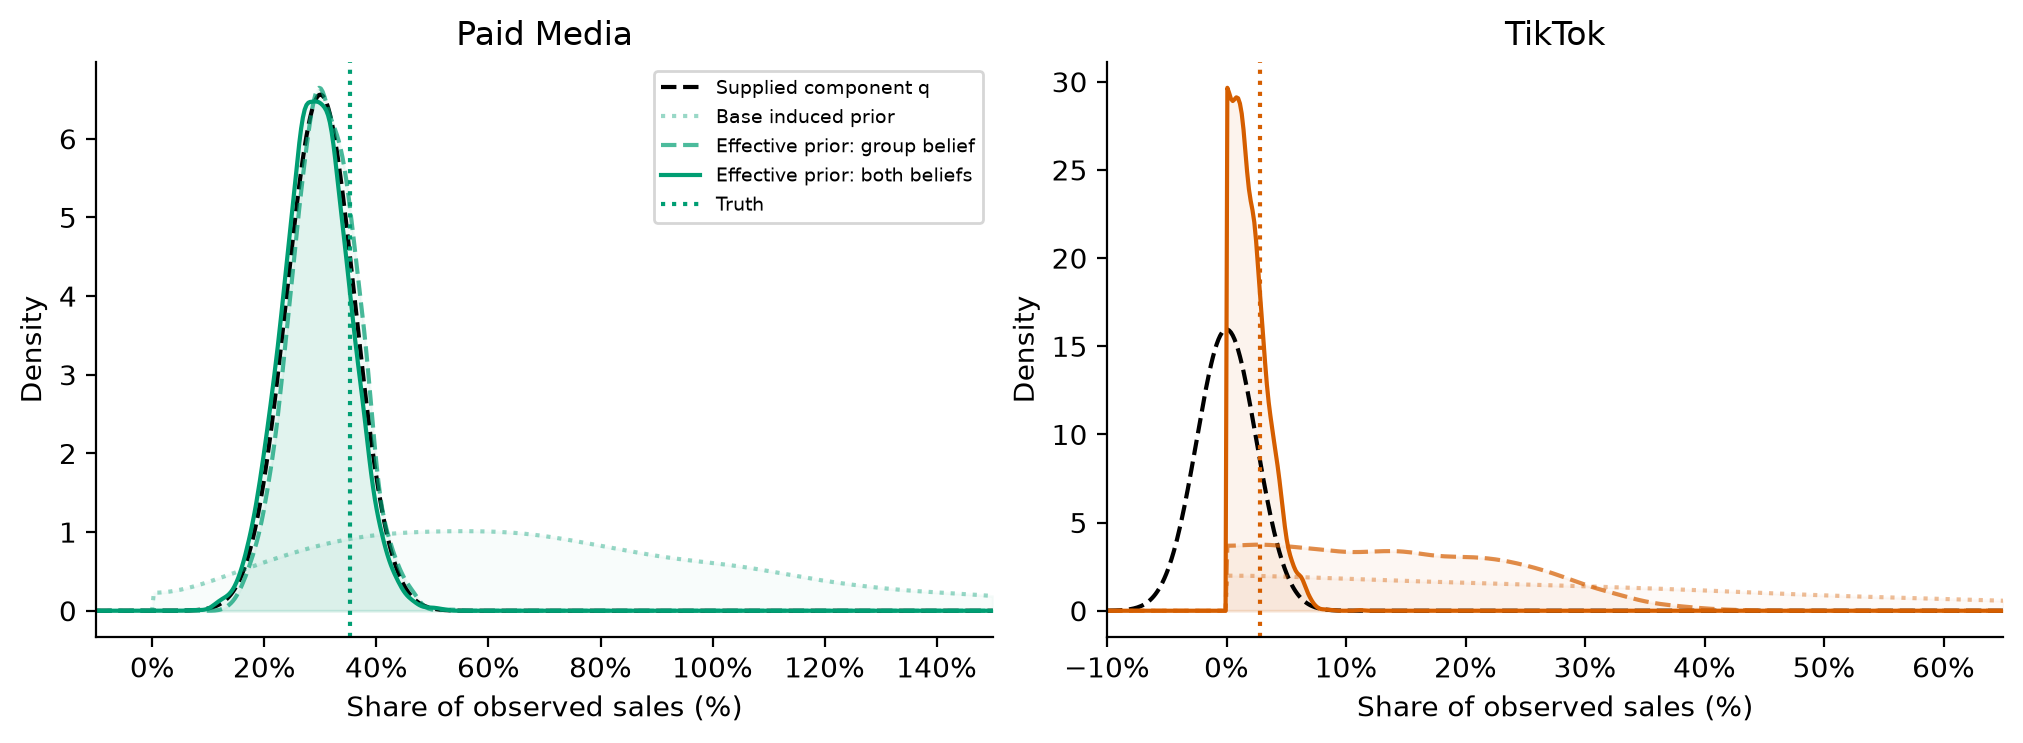

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, FIG_HEIGHT))
for ax, entity, component, upper in zip(
    axes,
    ["paid_media", "tiktok"],
    [paid_media_belief, tiktok_belief],
    [1.5, 0.65],
    strict=False,
):
    grid = np.linspace(-0.1, upper, 500)
    supplied = component.preliz.pdf(grid)
    ax.plot(grid, supplied, color="black", linestyle="--", label="Supplied component q")
    for label in VARIANTS:
        values = prior_shares[label][entity].values.ravel()
        kernel = gaussian_kde(values)
        density = np.where(grid >= 0, kernel(grid) + kernel(-grid), 0)
        alpha, ls = STYLES[label]
        ax.plot(
            grid,
            density,
            color=ENTITY_COLORS[entity],
            alpha=alpha,
            linestyle=ls,
            label="Base induced prior"
            if label == "Base"
            else f"Effective prior: {label.lower()}",
        )
        ax.fill_between(grid, density, color=ENTITY_COLORS[entity], alpha=0.07 * alpha)
    ax.axvline(
        true_shares[entity], color=ENTITY_COLORS[entity], linestyle=":", label="Truth"
    )
    ax.set(
        title=entity.replace("_", " ").title().replace("Tiktok", "TikTok"),
        xlabel="Share of observed sales (%)",
        ylabel="Density",
        xlim=(-0.1, upper),
    )
    ax.xaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=7)
plt.show()

**Caption:** Supplied Normal component densities, base induced share densities, and effective share priors sampled by MCMC. Shaded densities and line styles distinguish model variants within each target; vertical coloured lines mark known truth. Induced/effective densities use reflection KDE at zero to respect the model’s nonnegative support; sampled shares are unchanged. The supplied Normal curve retains its negative support. The base induced prior may extend beyond the displayed range.

The supplied curve and effective density are different objects. Even the group-only factor can change TikTok's induced prior, because the existing channel parameters jointly determine the group total. The individual factor adds information about allocation rather than imposing a complete set of channel proportions.

## Update the contribution breakdown

Fit the group-only and both-belief models to the **same** outcomes, retaining all existing priors. Compare each channel and the group in a common panel, with matching axes and the known truth.

In [9]:
for label in ["Group belief", "Both beliefs"]:
    models[label].fit(X, y, **SAMPLING)
posterior_shares = {label: shares(models[label].idata) for label in VARIANTS}

The two additional fits use the identical sampling settings and data. We can now compare the historical breakdown with uncertainty, not just posterior means.

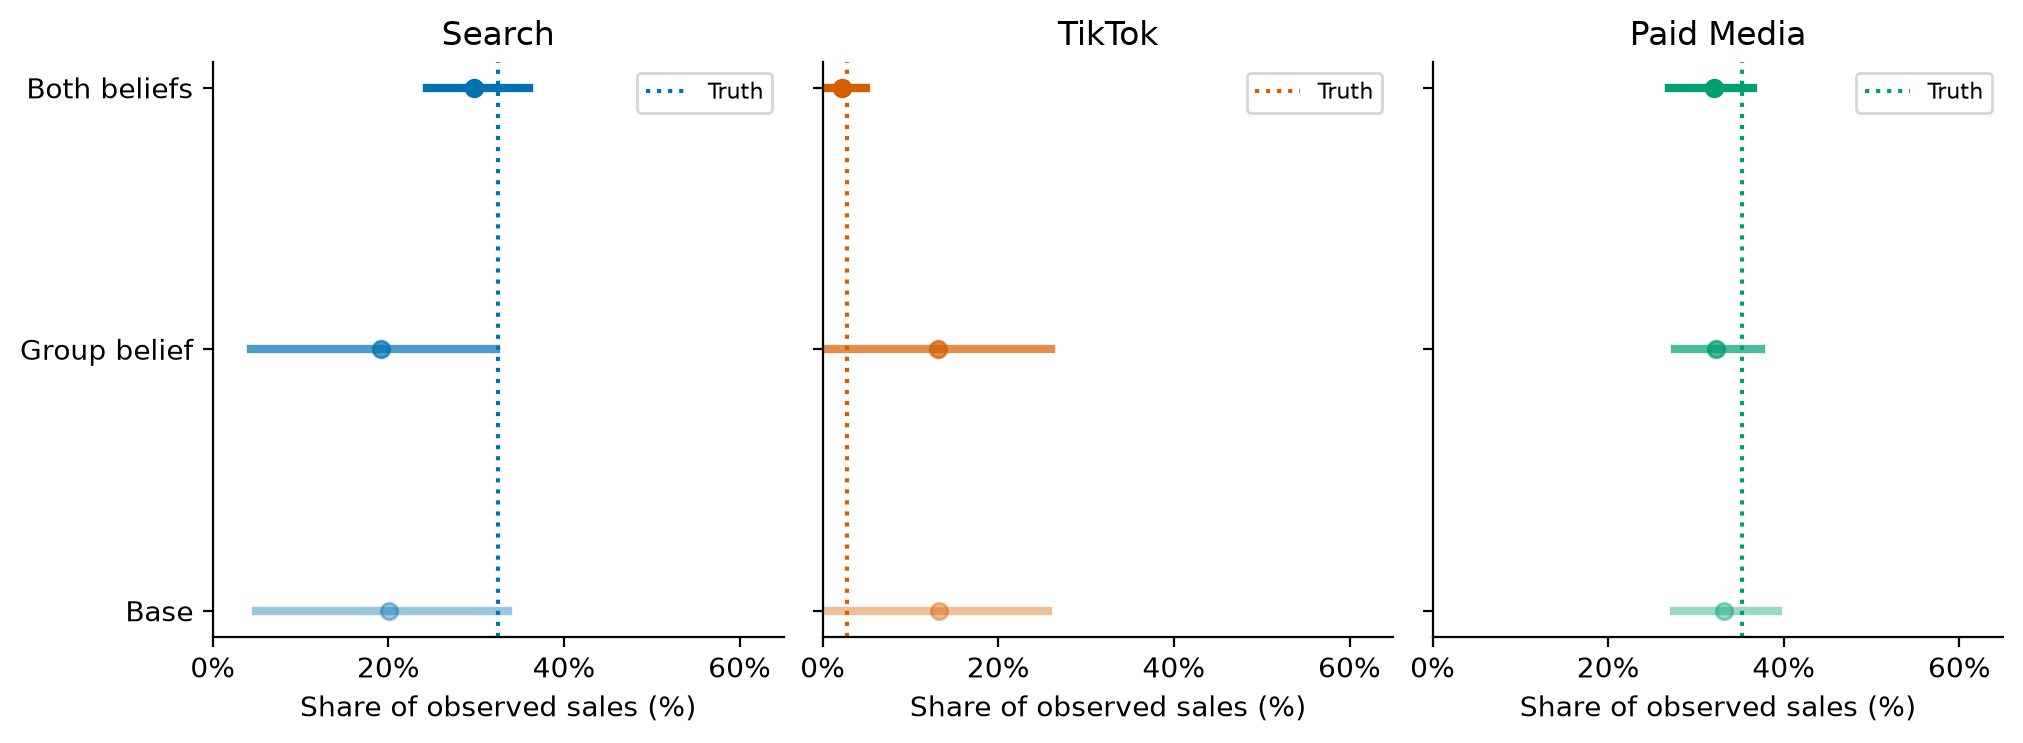

,Model,Target,Mean,HDI low,HDI high,HDI width
0,Base,search,20.0%,4.9%,33.6%,28.7%
1,Base,tiktok,13.2%,0.1%,25.7%,25.6%
2,Base,paid_media,33.2%,27.5%,39.4%,11.9%
3,Group belief,search,19.2%,4.3%,32.3%,27.9%
4,Group belief,tiktok,13.1%,0.0%,26.0%,26.0%
5,Group belief,paid_media,32.3%,27.6%,37.4%,9.9%
6,Both beliefs,search,29.8%,24.4%,36.0%,11.6%
7,Both beliefs,tiktok,2.2%,0.0%,5.0%,5.0%
8,Both beliefs,paid_media,32.0%,26.9%,36.5%,9.6%


In [10]:
def share_intervals(draws_by_variant, labels):
    _fig, axes = plt.subplots(
        1, 3, figsize=(FIG_WIDTH, FIG_HEIGHT), sharex=True, sharey=True
    )
    for ax, entity in zip(axes, ["search", "tiktok", "paid_media"], strict=False):
        color = ENTITY_COLORS[entity]
        for row, label in enumerate(labels):
            values = draws_by_variant[label][entity]
            lo, hi = interval(values)
            alpha, _ = STYLES[label]
            ax.plot([lo, hi], [row, row], color=color, alpha=alpha, linewidth=3)
            ax.plot(float(values.mean()), row, "o", color=color, alpha=alpha)
        ax.axvline(true_shares[entity], color=color, linestyle=":", label="Truth")
        ax.set(
            title=entity.replace("_", " ").title().replace("Tiktok", "TikTok"),
            xlabel="Share of observed sales (%)",
            xlim=(0, 0.65),
        )
        ax.set_yticks(range(len(labels)), labels)
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.legend(fontsize=8)
    plt.show()


share_intervals(posterior_shares, VARIANTS)
summary_rows = []
for label in VARIANTS:
    for entity in ["search", "tiktok", "paid_media"]:
        values = posterior_shares[label][entity]
        lo, hi = interval(values)
        summary_rows.append([label, entity, float(values.mean()), lo, hi, hi - lo])
share_table = pd.DataFrame(
    summary_rows,
    columns=["Model", "Target", "Mean", "HDI low", "HDI high", "HDI width"],
)
display(share_table.style.format({k: "{:.1%}" for k in share_table.columns[2:]}))

**Caption:** Posterior means and 94% HDIs of historical contribution shares under the three prior specifications. Panels are organized by target; vertical lines show known truth. The accompanying table reports interval widths.

Here the group belief changes the paid-media 94% HDI width only modestly, from about 12 to 10 percentage points: the data already identify that group relatively well. TikTok remains uncertain under the group-only model. Adding the individual belief reduces its HDI width from about 26 to 5 percentage points, with a posterior mean around 2.2% compared with the 2.8% truth. A group-total judgment concerns media versus baseline and does not by itself determine the within-media split. The individual TikTok judgment supplies different information. A small shift can be reasonable when a component agrees with what the model already learns or is broad; one factor can also matter greatly along a weakly identified direction. Counting factors versus sales observations does not measure influence.

## Assess the assumptions

Now replace the TikTok component with a confident, inaccurate belief around an 18% share. Keep the group belief, all other priors, and the data unchanged. A reasonable sales prediction alone cannot validate business knowledge about attribution.

In [11]:
wrong_mmm = build_mmm()
wrong_mmm.add_contribution_prior(
    name="paid_media_share",
    channels=["search", "tiktok"],
    scale="share",
    prior=paid_media_belief,
)
wrong_mmm.add_contribution_prior(
    name="tiktok_share",
    channels=["tiktok"],
    scale="share",
    prior=wrong_tiktok_belief,
)
wrong_mmm.fit(X, y, **SAMPLING)
models["Wrong belief"] = wrong_mmm
posterior_shares["Wrong belief"] = shares(wrong_mmm.idata)

The wrong-belief fit is ready. The next comparison includes prediction error against observed sales, contribution bias against known truth, and response curves. The response curves describe steady weekly spend after adstock has settled; normalized adstock leaves a constant input unchanged at that point.

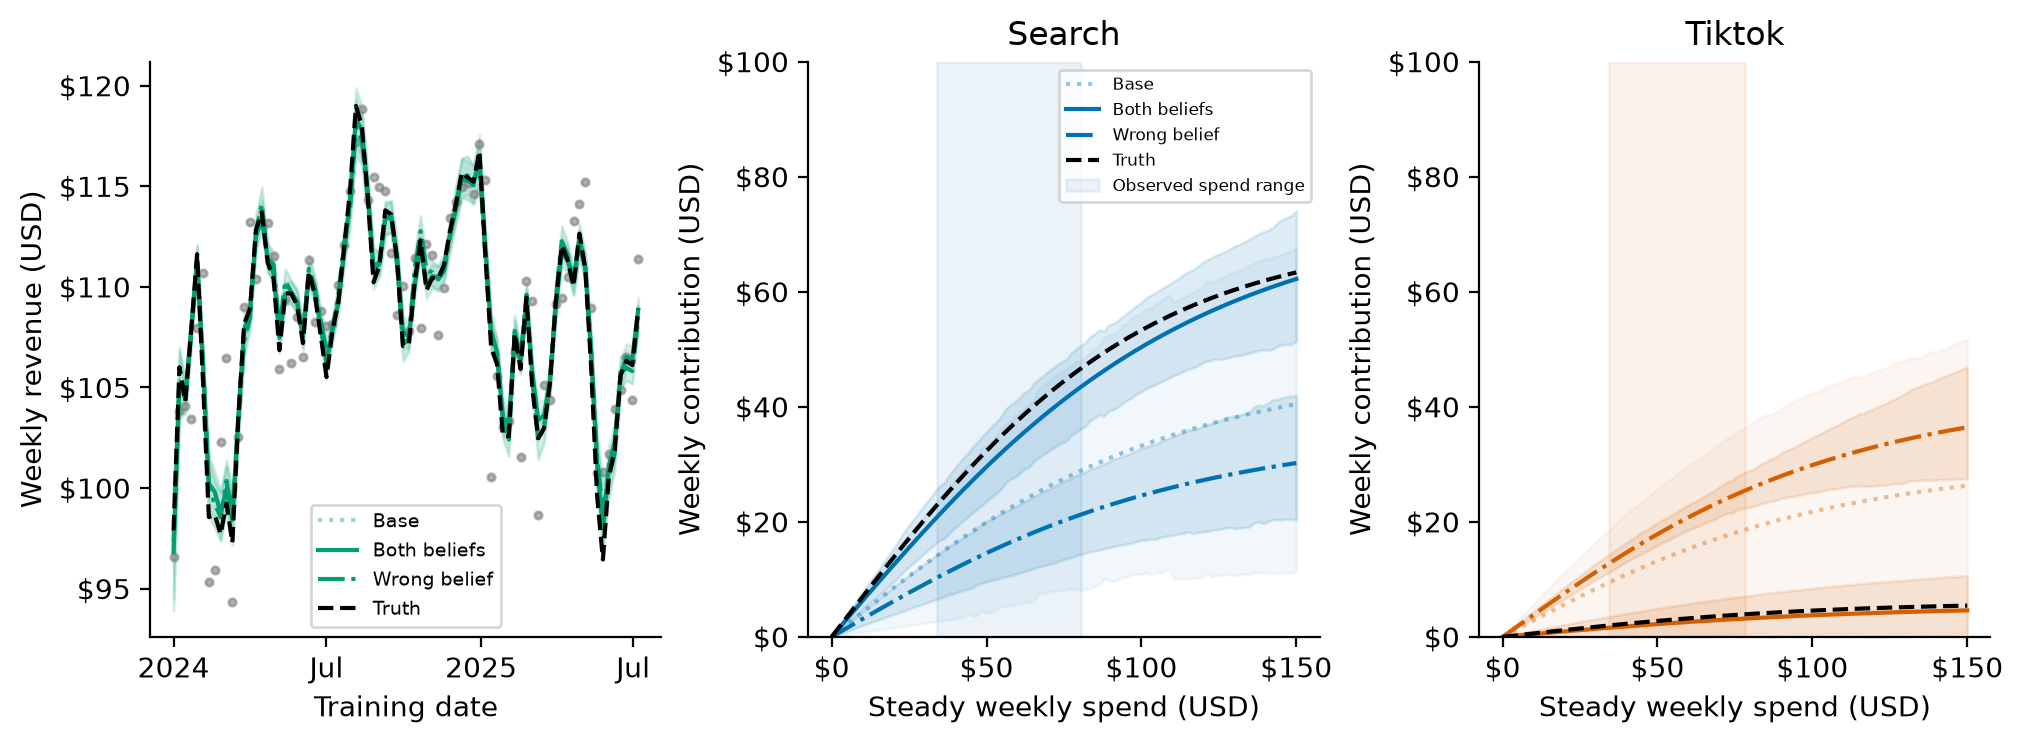

,Sales RMSE (USD),TikTok posterior mean,TikTok truth
Model,,,
Base,2.50,13.2%,2.8%
Group belief,2.50,13.1%,2.8%
Both beliefs,2.50,2.2%,2.8%
Wrong belief,2.51,17.9%,2.8%


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_WIDTH, FIG_HEIGHT))
for label in ["Base", "Both beliefs", "Wrong belief"]:
    posterior = models[label].idata.posterior
    mean_sales = (
        posterior.intercept_contribution * 100
        + posterior.channel_contribution_original_scale.sum("channel")
    )
    alpha, ls = STYLES[label]
    band(axes[0], X.date, mean_sales, MEDIA, label, alpha, ls)
axes[0].scatter(X.date, y, s=7, c="0.5", alpha=0.6)
axes[0].plot(X.date, true_mean, "k--", label="Truth")
axes[0].set(xlabel="Training date", ylabel="Weekly revenue (USD)")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].legend(fontsize=7)
spend_grid = np.linspace(0, 150, 100)
for j, (ax, entity) in enumerate(zip(axes[1:], ["search", "tiktok"], strict=False)):
    color = ENTITY_COLORS[entity]
    for label in ["Base", "Both beliefs", "Wrong belief"]:
        posterior = models[label].idata.posterior
        curves = (
            (
                100
                * saturation.function(
                    x=as_xtensor(spend_grid / 100, dims=("spend",)),
                    lam=as_xtensor(posterior.saturation_lam),
                    beta=as_xtensor(posterior.saturation_beta),
                )
            )
            .transpose("chain", "draw", "spend", "channel")
            .values.eval()
        )
        curve_draws = xr.DataArray(curves[..., j], dims=("chain", "draw", "spend"))
        alpha, ls = STYLES[label]
        band(ax, spend_grid, curve_draws, color, label, alpha, ls)
    true_curve = (
        (
            100
            * saturation.function(
                x=as_xtensor(spend_grid / 100, dims=("spend",)),
                lam=true_lam,
                beta=true_beta,
            )
        )
        .transpose("spend", "channel")
        .values.eval()[:, j]
    )
    ax.plot(spend_grid, true_curve, "k--", label="Truth")
    ax.axvspan(
        spend[:, j].min(),
        spend[:, j].max(),
        color=color,
        alpha=0.08,
        label="Observed spend range",
    )
    ax.set(
        title=entity.title(),
        xlabel="Steady weekly spend (USD)",
        ylabel="Weekly contribution (USD)",
        ylim=(0, 100),
    )
    ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
    ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[1].legend(fontsize=6)
format_dates(axes[0])
plt.show()

sensitivity = []
for label in ["Base", "Group belief", "Both beliefs", "Wrong belief"]:
    posterior = models[label].idata.posterior
    predicted = (
        posterior.intercept_contribution * 100
        + posterior.channel_contribution_original_scale.sum("channel")
    ).mean(("chain", "draw"))
    sensitivity.append(
        {
            "Model": label,
            "Sales RMSE (USD)": float(
                np.sqrt(np.mean((predicted.values - y.values) ** 2))
            ),
            "TikTok posterior mean": float(posterior_shares[label].tiktok.mean()),
            "TikTok truth": true_shares["tiktok"],
        }
    )
display(
    pd.DataFrame(sensitivity)
    .set_index("Model")
    .style.format(
        {
            "Sales RMSE (USD)": "{:.2f}",
            "TikTok posterior mean": "{:.1%}",
            "TikTok truth": "{:.1%}",
        }
    )
)

**Caption:** Conditional mean revenue and steady-spend response curves, with posterior means and 94% HDIs for base, useful-belief, and wrong-belief models. Dashed black curves show truth; shaded vertical regions show the training spend range. The table contrasts sales RMSE with TikTok attribution.

The wrong belief pushes TikTok's posterior mean to about 17.9%, far above its 2.8% true share, while sales RMSE changes only from about USD 2.50 to USD 2.51. Its response curve is correspondingly distorted despite similar sales predictions. The useful individual belief brings the historical allocation closer to truth, but response uncertainty still grows outside the observed spend range. Historical contribution is an integral along one spend path. Learning it does not establish marginal returns or identify response shapes far outside the observed range. The wrong belief is a sensitivity analysis, not a proposed business judgment.

In [13]:
diagnostics = []
for label, idata in [(k, v.idata) for k, v in models.items()] + [
    (f"Prior: {k}", v) for k, v in effective_priors.items()
]:
    parameters = [
        "intercept_contribution",
        "adstock_alpha",
        "saturation_lam",
        "saturation_beta",
        "y_sigma",
    ]
    summary = az.summary(idata, var_names=parameters, kind="diagnostics")
    diagnostics.append(
        {
            "Run": label,
            "Max R-hat": float(summary.r_hat.max()),
            "Min bulk ESS": float(summary.ess_bulk.min()),
            "Min tail ESS": float(summary.ess_tail.min()),
            "Divergences": int(idata.sample_stats.diverging.sum()),
        }
    )
diagnostics = pd.DataFrame(diagnostics).set_index("Run")
display(diagnostics)
assert (diagnostics["Max R-hat"] < 1.02).all()  # noqa: S101
assert (diagnostics["Min bulk ESS"] > 200).all()  # noqa: S101
assert (diagnostics["Min tail ESS"] > 200).all()  # noqa: S101
assert (diagnostics["Divergences"] == 0).all()  # noqa: S101

,Max R-hat,Min bulk ESS,Min tail ESS,Divergences
Run,,,,
Base,1.00,905.0,799.0,0
Group belief,1.00,742.0,794.0,0
Both beliefs,1.01,640.0,682.0,0
Wrong belief,1.00,887.0,1043.0,0
Prior: Group belief,1.00,1110.0,986.0,0
Prior: Both beliefs,1.00,1812.0,1335.0,0


All six runs pass the displayed checks: zero divergences, maximum R-hat at most 1.01, and minimum bulk ESS above 600. All reported runs must pass these checks before interpreting their comparisons. These are computational checks, not proof that the business beliefs or causal model are correct. There is no sampling test demanding a particular shift or exact truth recovery.

The empirical comparisons answer the influence question: inspect changes in the target's uncertainty and allocation alongside predictions. Broad, redundant knowledge can move estimates little; confident information on an ambiguous allocation can matter more. No guarantee of unchanged predictive fit or recovery of all transformation parameters follows.

## Usage recap

Build with real training outcomes, then call `mmm.add_contribution_prior(name=..., channels=[...], scale="share", prior=...)` for each sparse judgment, and fit normally. Use `scale="total"` for original-unit totals. Inspect effective priors with the prior-only MCMC workflow above, compare attribution and predictions, and challenge at least one assumption. Posterior predictive sampling from fitted parameter draws remains available through `mmm.sample_posterior_predictive(X)`.

The initial API accepts smooth real-line components, not Beta or hard caps. Treat a smooth upper-tail belief as probabilistic knowledge, never as an absolute prohibition. The named aggregates describe the frozen historical training path; they do not constrain every future spending scenario.

See the [`MMM` API](../../api/generated/pymc_marketing.mmm.mmm.MMM.rst) for the method and model lifecycle, [Prior Sensitivity](mmm_prior_sensitivity.ipynb) for further checks, and [confounding with lift tests](mmm_roas.ipynb) for the separate problem of latent spend–sales confounding and experimental evidence.

In [14]:
%load_ext watermark
%watermark -n -u -v -iv -w

Last updated: Thu, 15 Oct 2026

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.17.1

IPython       : 9.17.1
arviz         : 1.2.0
graphviz      : 0.21
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
pytensor      : 3.3.2
scipy         : 1.18.1
seaborn       : 0.13.2
xarray        : 2026.4.0

Watermark: 2.6.0

